In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
train = pd.read_csv(
    r"C:\Users\ariya\loan_predict\train.csv"
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("Shape:", train.shape)

Shape: (593994, 13)


In [4]:
train.head()

,id,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,gender,marital_status,education_level,employment_status,loan_purpose,grade_subgrade,loan_paid_back
0,0,29367.99,0.084,736,2528.42,13.67,Female,Single,High School,Self-employed,Other,C3,1.0
1,1,22108.02,0.166,636,4593.10,12.92,Male,Married,Master's,Employed,Debt consolidation,D3,0.0
2,2,49566.20,0.097,694,17005.15,9.76,Male,Single,High School,Employed,Debt consolidation,C5,1.0
3,3,46858.25,0.065,533,4682.48,16.10,Female,Single,High School,Employed,Debt consolidation,F1,1.0
4,4,25496.70,0.053,665,12184.43,10.21,Male,Married,High School,Employed,Other,D1,1.0


In [5]:
train.tail()

,id,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,gender,marital_status,education_level,employment_status,loan_purpose,grade_subgrade,loan_paid_back
593989,593989,23004.26,0.152,703,20958.37,10.92,Female,Single,High School,Employed,Business,C3,1.0
593990,593990,35289.43,0.105,559,3257.24,14.62,Male,Single,Bachelor's,Employed,Debt consolidation,F5,1.0
593991,593991,47112.64,0.072,675,929.27,14.13,Female,Married,Bachelor's,Employed,Debt consolidation,C1,1.0
593992,593992,76748.44,0.067,740,16290.40,9.87,Male,Single,Bachelor's,Employed,Debt consolidation,B2,1.0
593993,593993,48959.52,0.096,752,7707.73,10.31,Male,Married,High School,Employed,Education,B3,1.0


In [6]:
train.columns

Index(['id', 'annual_income', 'debt_to_income_ratio', 'credit_score',
       'loan_amount', 'interest_rate', 'gender', 'marital_status',
       'education_level', 'employment_status', 'loan_purpose',
       'grade_subgrade', 'loan_paid_back'],
      dtype='object')

In [7]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 593994 entries, 0 to 593993
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    593994 non-null  int64  
 1   annual_income         593994 non-null  float64
 2   debt_to_income_ratio  593994 non-null  float64
 3   credit_score          593994 non-null  int64  
 4   loan_amount           593994 non-null  float64
 5   interest_rate         593994 non-null  float64
 6   gender                593994 non-null  object 
 7   marital_status        593994 non-null  object 
 8   education_level       593994 non-null  object 
 9   employment_status     593994 non-null  object 
 10  loan_purpose          593994 non-null  object 
 11  grade_subgrade        593994 non-null  object 
 12  loan_paid_back        593994 non-null  float64
dtypes: float64(5), int64(2), object(6)
memory usage: 58.9+ MB


In [8]:
train.isnull().sum()

id                      0
annual_income           0
debt_to_income_ratio    0
credit_score            0
loan_amount             0
interest_rate           0
gender                  0
marital_status          0
education_level         0
employment_status       0
loan_purpose            0
grade_subgrade          0
loan_paid_back          0
dtype: int64

In [9]:
train.isnull().sum().sort_values(ascending=False)

id                      0
annual_income           0
debt_to_income_ratio    0
credit_score            0
loan_amount             0
interest_rate           0
gender                  0
marital_status          0
education_level         0
employment_status       0
loan_purpose            0
grade_subgrade          0
loan_paid_back          0
dtype: int64

In [10]:
print("Duplicate rows:", train.duplicated().sum())

Duplicate rows: 0


In [11]:
print("Duplicate IDs:", train['id'].duplicated().sum())

Duplicate IDs: 0


In [12]:
print("Target column:", 'loan_paid_back')

Target column: loan_paid_back


In [13]:
train['loan_paid_back'].value_counts()

loan_paid_back
1.0    474494
0.0    119500
Name: count, dtype: int64

In [14]:
train['loan_paid_back'].value_counts(normalize=True) * 100

loan_paid_back
1.0    79.881952
0.0    20.118048
Name: proportion, dtype: float64

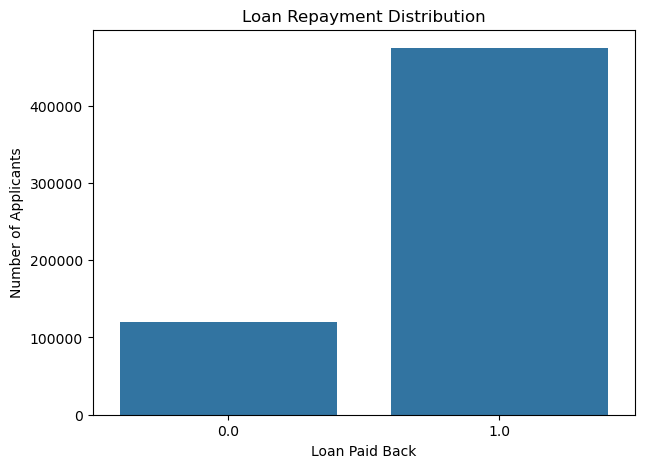

In [15]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=train,
    x='loan_paid_back'
)

plt.title('Loan Repayment Distribution')
plt.xlabel('Loan Paid Back')
plt.ylabel('Number of Applicants')

plt.show()

In [16]:
train.dtypes

id                        int64
annual_income           float64
debt_to_income_ratio    float64
credit_score              int64
loan_amount             float64
interest_rate           float64
gender                   object
marital_status           object
education_level          object
employment_status        object
loan_purpose             object
grade_subgrade           object
loan_paid_back          float64
dtype: object

In [17]:
train.describe()

,id,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,loan_paid_back
count,593994.000000,593994.000000,593994.000000,593994.000000,593994.000000,593994.000000,593994.000000
mean,296996.500000,48212.202976,0.120696,680.916009,15020.297629,12.356345,0.798820
std,171471.442235,26711.942078,0.068573,55.424956,6926.530568,2.008959,0.400883
min,0.000000,6002.430000,0.011000,395.000000,500.090000,3.200000,0.000000
25%,148498.250000,27934.400000,0.072000,646.000000,10279.620000,10.990000,1.000000
50%,296996.500000,46557.680000,0.096000,682.000000,15000.220000,12.370000,1.000000
75%,445494.750000,60981.320000,0.156000,719.000000,18858.580000,13.680000,1.000000
max,593993.000000,393381.740000,0.627000,849.000000,48959.950000,20.990000,1.000000


In [18]:
categorical_columns = [
    'gender',
    'marital_status',
    'education_level',
    'employment_status',
    'loan_purpose',
    'grade_subgrade'
]

for col in categorical_columns:
    print("\n" + "="*50)
    print(col)
    print(train[col].value_counts())


gender
gender
Female    306175
Male      284091
Other       3728
Name: count, dtype: int64

marital_status
marital_status
Single      288843
Married     277239
Divorced     21312
Widowed       6600
Name: count, dtype: int64

education_level
education_level
Bachelor's     279606
High School    183592
Master's        93097
Other           26677
PhD             11022
Name: count, dtype: int64

employment_status
employment_status
Employed         450645
Unemployed        62485
Self-employed     52480
Retired           16453
Student           11931
Name: count, dtype: int64

loan_purpose
loan_purpose
Debt consolidation    324695
Other                  63874
Car                    58108
Home                   44118
Education              36641
Business               35303
Medical                22806
Vacation                8449
Name: count, dtype: int64

grade_subgrade
grade_subgrade
C3    58695
C4    55957
C2    54443
C1    53363
C5    53317
D1    37029
D3    36694
D4    35097
D2    34432

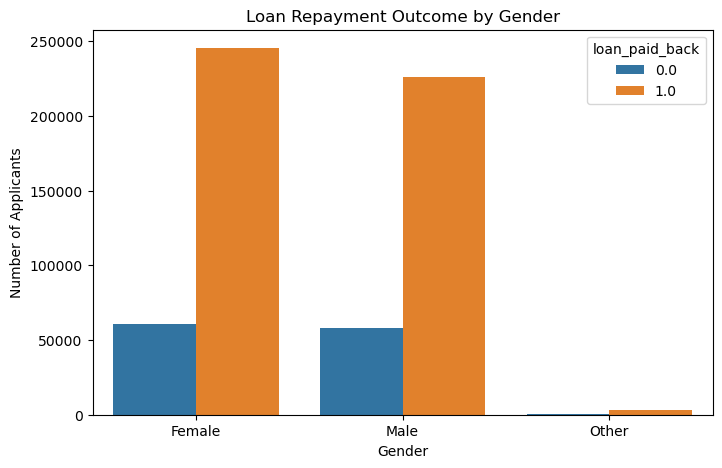

In [19]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train,
    x='gender',
    hue='loan_paid_back'
)

plt.title('Loan Repayment Outcome by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Applicants')

plt.show()

In [20]:
gender_rate = (
    train.groupby('gender')['loan_paid_back']
    .mean()
    .sort_values(ascending=False)
)

print(gender_rate)

gender
Female    0.801708
Male      0.795752
Other     0.795333
Name: loan_paid_back, dtype: float64


In [21]:
gender_rate_percent = gender_rate * 100

print(gender_rate_percent)

gender
Female    80.170817
Male      79.575207
Other     79.533262
Name: loan_paid_back, dtype: float64


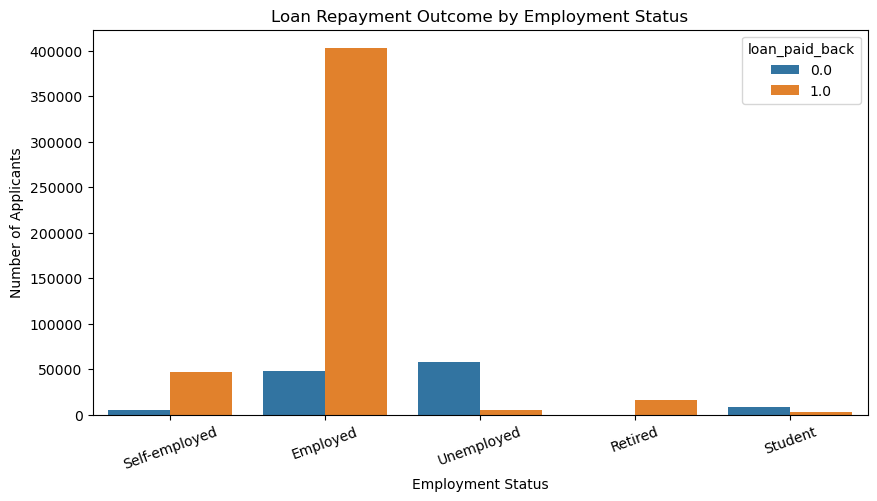

In [22]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=train,
    x='employment_status',
    hue='loan_paid_back'
)

plt.title('Loan Repayment Outcome by Employment Status')
plt.xlabel('Employment Status')
plt.ylabel('Number of Applicants')

plt.xticks(rotation=20)

plt.show()

In [23]:
employment_rate = (
    train.groupby('employment_status')['loan_paid_back']
    .mean()
    .sort_values(ascending=False) * 100
)

print(employment_rate)

employment_status
Retired          99.720416
Self-employed    89.845655
Employed         89.414506
Student          26.351521
Unemployed        7.761863
Name: loan_paid_back, dtype: float64


In [24]:
loan_purpose_rate = (
    train.groupby('loan_purpose')['loan_paid_back']
    .mean()
    .sort_values(ascending=False) * 100
)

print(loan_purpose_rate)

loan_purpose
Home                  82.322408
Business              81.310370
Other                 80.237655
Car                   80.062986
Debt consolidation    79.691095
Vacation              79.607054
Medical               77.808471
Education             77.705303
Name: loan_paid_back, dtype: float64


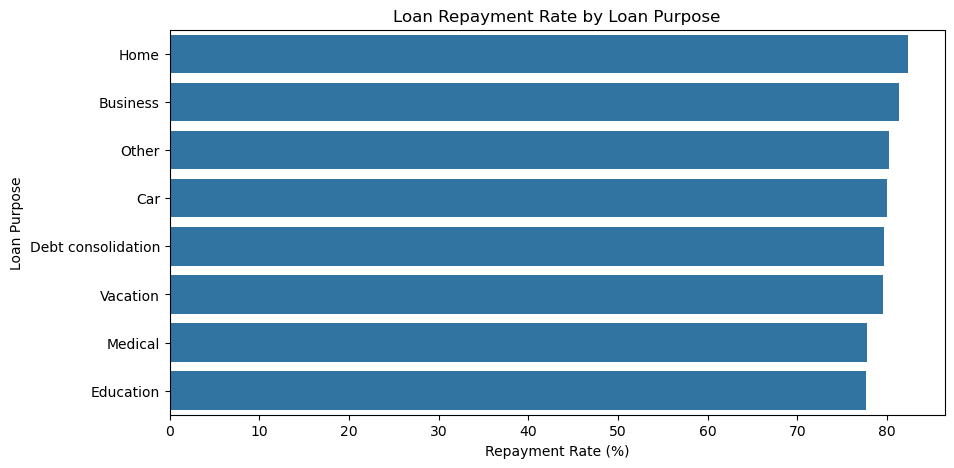

In [25]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=loan_purpose_rate.values,
    y=loan_purpose_rate.index
)

plt.title('Loan Repayment Rate by Loan Purpose')
plt.xlabel('Repayment Rate (%)')
plt.ylabel('Loan Purpose')

plt.show()

In [26]:
education_rate = (
    train.groupby('education_level')['loan_paid_back']
    .mean()
    .sort_values(ascending=False) * 100
)

print(education_rate)

education_level
PhD            83.006714
High School    80.969759
Other          80.278892
Master's       80.234594
Bachelor's     78.889223
Name: loan_paid_back, dtype: float64


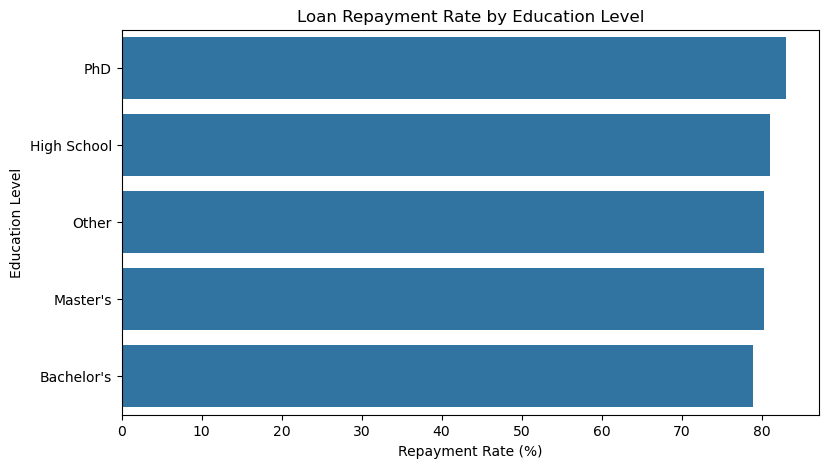

In [27]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=education_rate.values,
    y=education_rate.index
)

plt.title('Loan Repayment Rate by Education Level')
plt.xlabel('Repayment Rate (%)')
plt.ylabel('Education Level')

plt.show()

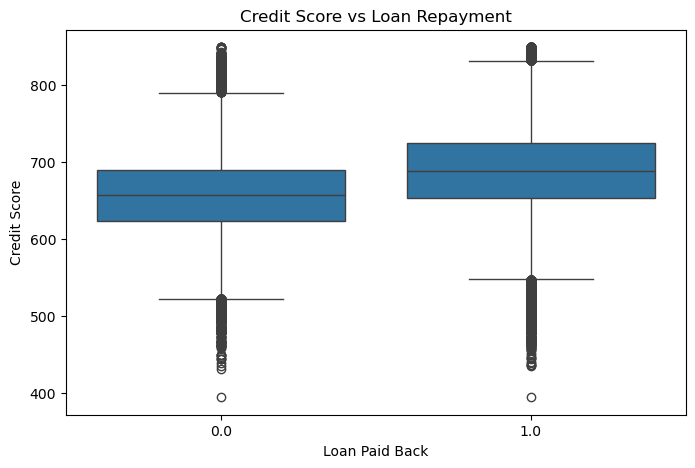

In [28]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train,
    x='loan_paid_back',
    y='credit_score'
)

plt.title('Credit Score vs Loan Repayment')
plt.xlabel('Loan Paid Back')
plt.ylabel('Credit Score')

plt.show()

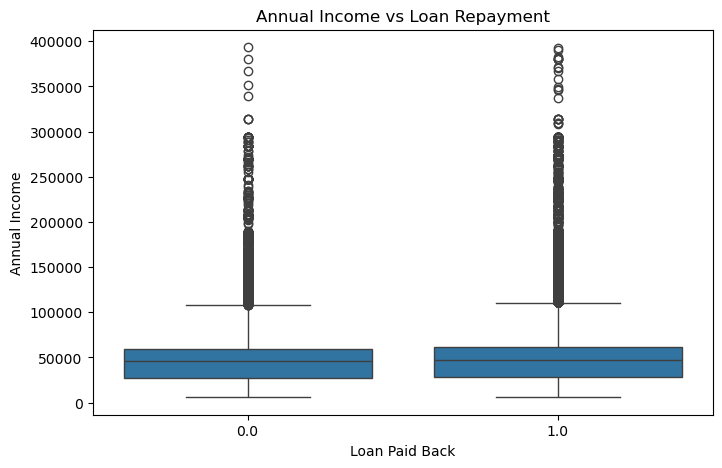

In [29]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train,
    x='loan_paid_back',
    y='annual_income'
)

plt.title('Annual Income vs Loan Repayment')
plt.xlabel('Loan Paid Back')
plt.ylabel('Annual Income')

plt.show()

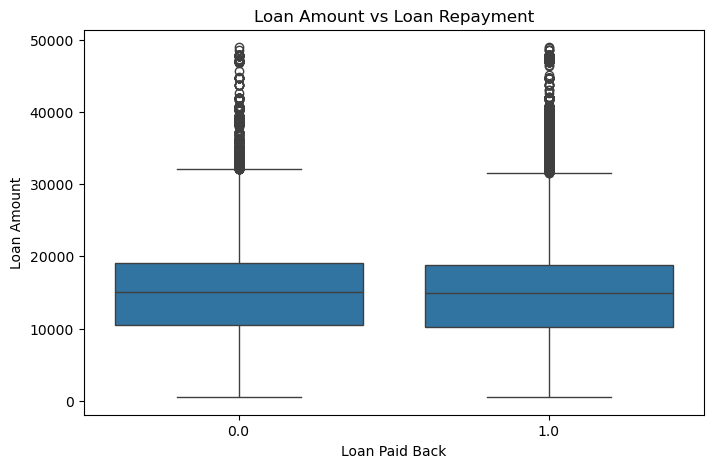

In [30]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train,
    x='loan_paid_back',
    y='loan_amount'
)

plt.title('Loan Amount vs Loan Repayment')
plt.xlabel('Loan Paid Back')
plt.ylabel('Loan Amount')

plt.show()

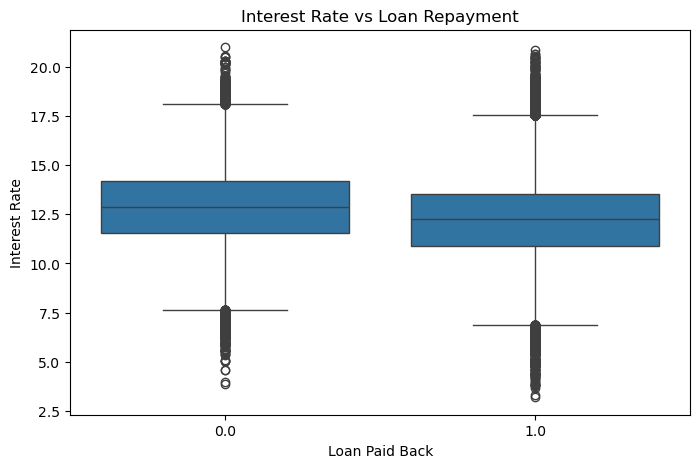

In [31]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train,
    x='loan_paid_back',
    y='interest_rate'
)

plt.title('Interest Rate vs Loan Repayment')
plt.xlabel('Loan Paid Back')
plt.ylabel('Interest Rate')

plt.show()

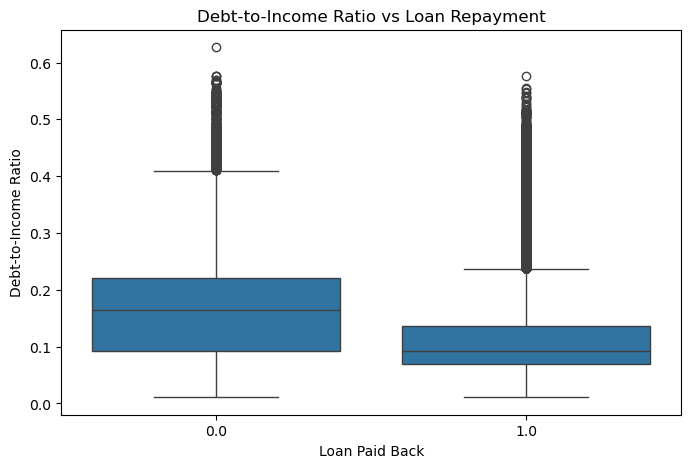

In [32]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train,
    x='loan_paid_back',
    y='debt_to_income_ratio'
)

plt.title('Debt-to-Income Ratio vs Loan Repayment')
plt.xlabel('Loan Paid Back')
plt.ylabel('Debt-to-Income Ratio')

plt.show()

In [33]:
numeric_columns = [
    'annual_income',
    'debt_to_income_ratio',
    'credit_score',
    'loan_amount',
    'interest_rate',
    'loan_paid_back'
]

correlation = train[numeric_columns].corr()

print(correlation)

                      annual_income  debt_to_income_ratio  credit_score  \
annual_income              1.000000              0.000553      0.001509   
debt_to_income_ratio       0.000553              1.000000     -0.061617   
credit_score               0.001509             -0.061617      1.000000   
loan_amount               -0.003407             -0.008236     -0.005761   
interest_rate             -0.002507              0.030316     -0.538335   
loan_paid_back             0.006326             -0.335680      0.234560   

                      loan_amount  interest_rate  loan_paid_back  
annual_income           -0.003407      -0.002507        0.006326  
debt_to_income_ratio    -0.008236       0.030316       -0.335680  
credit_score            -0.005761      -0.538335        0.234560  
loan_amount              1.000000      -0.001174       -0.003762  
interest_rate           -0.001174       1.000000       -0.131184  
loan_paid_back          -0.003762      -0.131184        1.000000  


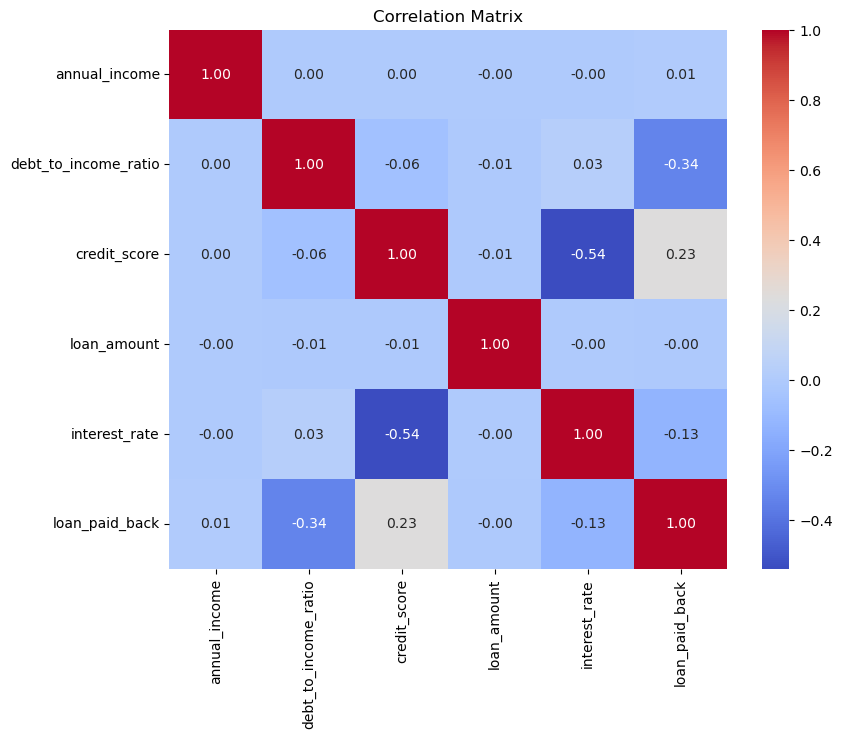

In [34]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Correlation Matrix')

plt.show()

In [35]:
df = train.drop(columns=['id'])

print("Shape:", df.shape)

Shape: (593994, 12)


In [36]:
X = df.drop(columns=['loan_paid_back'])
y = df['loan_paid_back']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (593994, 11)
y shape: (593994,)


In [37]:
categorical_features = [
    'gender',
    'marital_status',
    'education_level',
    'employment_status',
    'loan_purpose',
    'grade_subgrade'
]

numerical_features = [
    'annual_income',
    'debt_to_income_ratio',
    'credit_score',
    'loan_amount',
    'interest_rate'
]

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['gender', 'marital_status', 'education_level', 'employment_status', 'loan_purpose', 'grade_subgrade']

Numerical Features:
['annual_income', 'debt_to_income_ratio', 'credit_score', 'loan_amount', 'interest_rate']


In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [39]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (475195, 11)
X_test : (118799, 11)
y_train: (475195,)
y_test : (118799,)


In [40]:
print("Training distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training distribution:
loan_paid_back
1.0    79.881943
0.0    20.118057
Name: proportion, dtype: float64

Testing distribution:
loan_paid_back
1.0    79.881986
0.0    20.118014
Name: proportion, dtype: float64


In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            numerical_features
        ),
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        )
    ]
)

In [42]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

In [43]:
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [44]:
y_pred_lr = logistic_model.predict(X_test)

y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

print(y_pred_lr[:10])

[1. 1. 1. 1. 1. 1. 1. 1. 0. 0.]


In [45]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", accuracy_lr)
print("Precision:", precision_lr)
print("Recall   :", recall_lr)
print("F1 Score :", f1_lr)

Logistic Regression Results
---------------------------
Accuracy : 0.8614213924359633
Precision: 0.9383172765272593
Recall   : 0.8846773938608415
F1 Score : 0.9107081839531819


In [46]:
from sklearn.metrics import roc_auc_score

roc_auc_lr = roc_auc_score(
    y_test,
    y_prob_lr
)

print("ROC-AUC  :", roc_auc_lr)

ROC-AUC  : 0.9106886303831234


In [47]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_lr = confusion_matrix(
    y_test,
    y_pred_lr
)

print(cm_lr)

[[18381  5519]
 [10944 83955]]


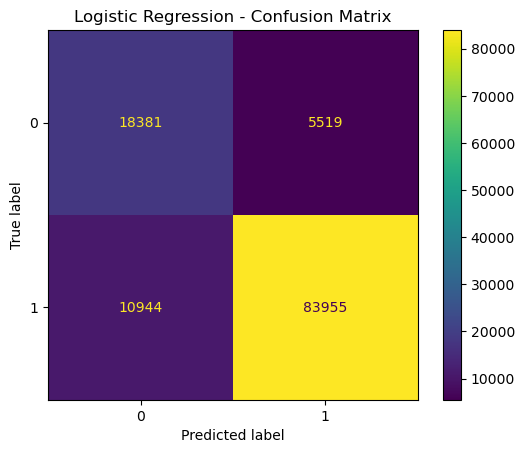

In [48]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr
)

disp.plot()

plt.title('Logistic Regression - Confusion Matrix')
plt.show()

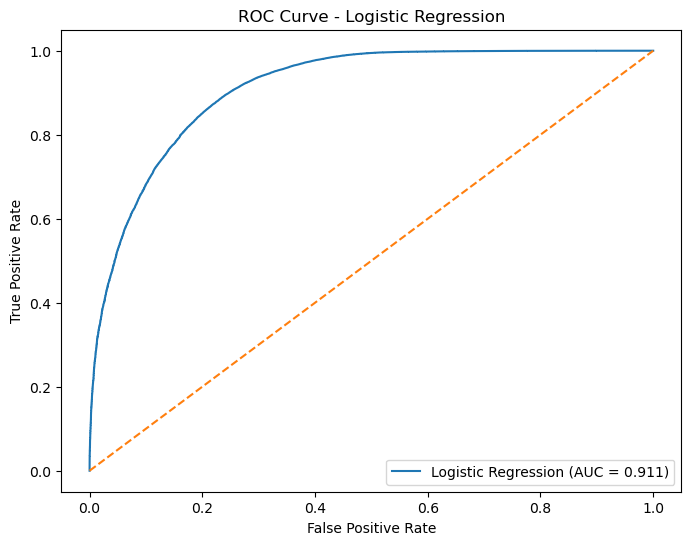

In [49]:
from sklearn.metrics import roc_curve

fpr_lr, tpr_lr, thresholds_lr = roc_curve(
    y_test,
    y_prob_lr
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f'Logistic Regression (AUC = {roc_auc_lr:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')

plt.legend()

plt.show()

In [50]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

decision_tree = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(
        max_depth=10,
        random_state=42,
        class_weight='balanced'
    ))
])

decision_tree.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [51]:
y_pred_dt = decision_tree.predict(X_test)

y_prob_dt = decision_tree.predict_proba(X_test)[:, 1]

print(y_pred_dt[:10])

[1. 1. 1. 1. 1. 1. 1. 1. 0. 0.]


In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
roc_auc_dt = roc_auc_score(y_test, y_prob_dt)

print("Decision Tree Results")
print("---------------------")
print("Accuracy :", accuracy_dt)
print("Precision:", precision_dt)
print("Recall   :", recall_dt)
print("F1 Score :", f1_dt)
print("ROC-AUC  :", roc_auc_dt)

cm_dt = confusion_matrix(y_test, y_pred_dt)

print("\nConfusion Matrix:")
print(cm_dt)

Decision Tree Results
---------------------
Accuracy : 0.861690754972685
Precision: 0.940950368638734
Recall   : 0.8822221519720966
F1 Score : 0.9106403806934058
ROC-AUC  : 0.9111954570419527

Confusion Matrix:
[[18646  5254]
 [11177 83722]]


In [53]:
from sklearn.ensemble import RandomForestClassifier

random_forest = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        class_weight='balanced'
    ))
])

random_forest.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [54]:
y_pred_rf = random_forest.predict(X_test)

y_prob_rf = random_forest.predict_proba(X_test)[:, 1]

print(y_pred_rf[:10])

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [55]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Results")
print("---------------------")
print("Accuracy :", accuracy_rf)
print("Precision:", precision_rf)
print("Recall   :", recall_rf)
print("F1 Score :", f1_rf)
print("ROC-AUC  :", roc_auc_rf)

cm_rf = confusion_matrix(y_test, y_pred_rf)

print("\nConfusion Matrix:")
print(cm_rf)

Random Forest Results
---------------------
Accuracy : 0.9009250919620535
Precision: 0.902339628485969
Recall   : 0.9822864308369951
F1 Score : 0.9406173375175323
ROC-AUC  : 0.9070020928658749

Confusion Matrix:
[[13811 10089]
 [ 1681 93218]]


In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

train = pd.read_csv(
    r"C:\Users\ariya\loan_predict\train.csv"
)

df = train.drop(columns=['id'])

X = df.drop(columns=['loan_paid_back'])
y = df['loan_paid_back']

categorical_features = [
    'gender',
    'marital_status',
    'education_level',
    'employment_status',
    'loan_purpose',
    'grade_subgrade'
]

numerical_features = [
    'annual_income',
    'debt_to_income_ratio',
    'credit_score',
    'loan_amount',
    'interest_rate'
]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

print("Project 2 ML setup restored!")
print(X_train.shape)
print(X_test.shape)

Project 2 ML setup restored!
(475195, 11)
(118799, 11)


In [4]:
X_svm, _, y_svm, _ = train_test_split(
    X_train,
    y_train,
    train_size=100000,
    random_state=42,
    stratify=y_train
)

print("SVM training data:", X_svm.shape)
print("SVM target data:", y_svm.shape)

print("\nClass distribution:")
print(y_svm.value_counts(normalize=True) * 100)

SVM training data: (100000, 11)
SVM target data: (100000,)

Class distribution:
loan_paid_back
1.0    79.882
0.0    20.118
Name: proportion, dtype: float64


In [3]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Load dataset
train = pd.read_csv(r"C:\Users\ariya\loan_predict\train.csv")

# Remove ID
df = train.drop(columns=['id'])

# Features and target
X = df.drop(columns=['loan_paid_back'])
y = df['loan_paid_back']

# Feature lists
categorical_features = [
    'gender',
    'marital_status',
    'education_level',
    'employment_status',
    'loan_purpose',
    'grade_subgrade'
]

numerical_features = [
    'annual_income',
    'debt_to_income_ratio',
    'credit_score',
    'loan_amount',
    'interest_rate'
]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

print("ML setup restored!")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

ML setup restored!
X_train: (475195, 11)
X_test : (118799, 11)


In [4]:
from sklearn.model_selection import train_test_split

X_svm, _, y_svm, _ = train_test_split(
    X_train,
    y_train,
    train_size=100000,
    random_state=42,
    stratify=y_train
)

print("SVM training data:", X_svm.shape)
print("SVM target data:", y_svm.shape)

SVM training data: (100000, 11)
SVM target data: (100000,)


In [5]:
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

svm_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearSVC(
        class_weight='balanced',
        random_state=42,
        max_iter=5000
    ))
])

svm_model.fit(X_svm, y_svm)

print("SVM trained successfully!")

SVM trained successfully!


In [6]:
y_pred_svm = svm_model.predict(X_test)
y_score_svm = svm_model.decision_function(X_test)

print("SVM predictions generated!")

SVM predictions generated!


In [7]:
y_pred_svm = svm_model.predict(X_test)

y_score_svm = svm_model.decision_function(X_test)

print("SVM predictions generated!")
print(y_pred_svm[:10])

SVM predictions generated!
[1. 1. 1. 1. 1. 1. 1. 1. 0. 0.]


In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm)
recall_svm = recall_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)
roc_auc_svm = roc_auc_score(y_test, y_score_svm)

print("SVM Results")
print("-----------")
print("Accuracy :", accuracy_svm)
print("Precision:", precision_svm)
print("Recall   :", recall_svm)
print("F1 Score :", f1_svm)
print("ROC-AUC  :", roc_auc_svm)

cm_svm = confusion_matrix(y_test, y_pred_svm)

print("\nConfusion Matrix:")
print(cm_svm)

SVM Results
-----------
Accuracy : 0.8663877642067694
Precision: 0.9362799222683509
Recall   : 0.8935499847205977
F1 Score : 0.91441604166779
ROC-AUC  : 0.9105041700136516

Confusion Matrix:
[[18129  5771]
 [10102 84797]]


In [10]:
accuracy_lr = 0.8614213924359633
precision_lr = 0.9383172765272593
recall_lr = 0.8846773938608415
f1_lr = 0.9107081839531819

accuracy_dt = 0.861690754972685
precision_dt = 0.940950368638734
recall_dt = 0.8822221519720966
f1_dt = 0.9106403806934058
roc_auc_dt = 0.9111954570419527

accuracy_rf = 0.9009250919620535
precision_rf = 0.902339628485969
recall_rf = 0.9822864308369951
f1_rf = 0.9406173375175323
roc_auc_rf = 0.9070020928658749

accuracy_svm = 0.8663877642067694
precision_svm = 0.9362799222683509
recall_svm = 0.8935499847205977
f1_svm = 0.91441604166779
roc_auc_svm = 0.9105041700136516

print("All model results restored!")

All model results restored!


In [13]:
import numpy as np
import pandas as pd

In [15]:
results_df = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'SVM'
    ],
    'Accuracy': [
        accuracy_lr,
        accuracy_dt,
        accuracy_rf,
        accuracy_svm
    ],
    'Precision': [
        precision_lr,
        precision_dt,
        precision_rf,
        precision_svm
    ],
    'Recall': [
        recall_lr,
        recall_dt,
        recall_rf,
        recall_svm
    ],
    'F1 Score': [
        f1_lr,
        f1_dt,
        f1_rf,
        f1_svm
    ],
    'ROC-AUC': [
        np.nan,
        roc_auc_dt,
        roc_auc_rf,
        roc_auc_svm
    ]
})

results_percentage = results_df.copy()

metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1 Score',
    'ROC-AUC'
]

results_percentage[metrics] = (
    results_percentage[metrics] * 100
).round(2)

results_percentage

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,86.14,93.83,88.47,91.07,NaN
1,Decision Tree,86.17,94.10,88.22,91.06,91.12
2,Random Forest,90.09,90.23,98.23,94.06,90.70
3,SVM,86.64,93.63,89.35,91.44,91.05


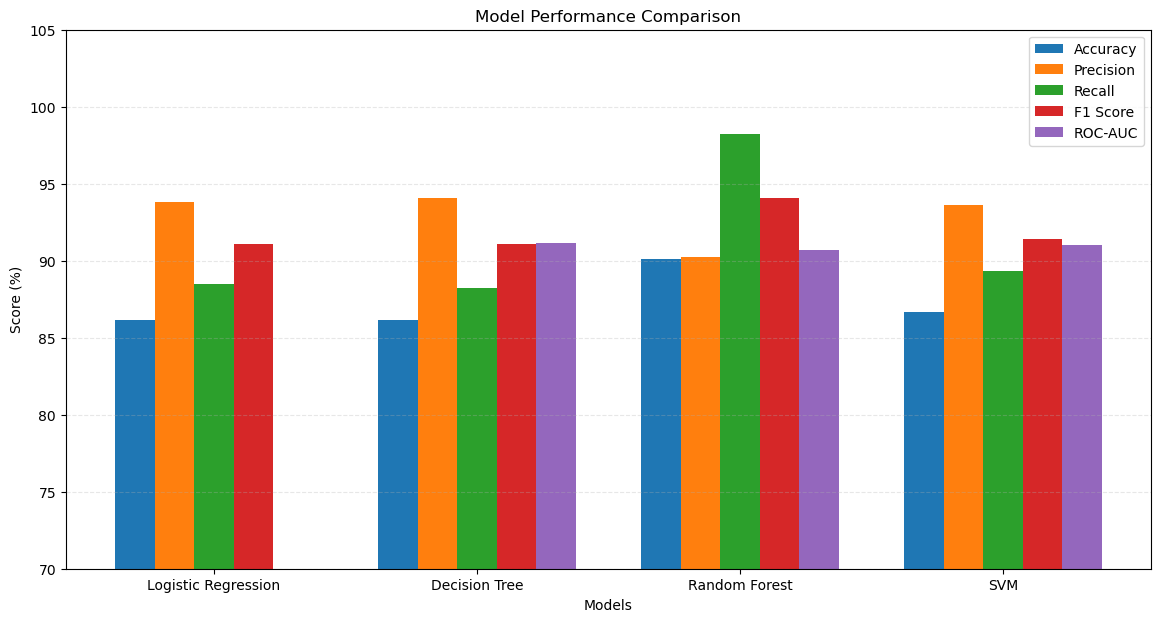

In [16]:
import matplotlib.pyplot as plt
import numpy as np

models = [
    'Logistic Regression',
    'Decision Tree',
    'Random Forest',
    'SVM'
]

accuracy = [86.14, 86.17, 90.09, 86.64]
precision = [93.83, 94.10, 90.23, 93.63]
recall = [88.47, 88.22, 98.23, 89.35]
f1 = [91.07, 91.06, 94.06, 91.44]
roc_auc = [np.nan, 91.12, 90.70, 91.05]

x = np.arange(len(models))
width = 0.15

plt.figure(figsize=(14, 7))

plt.bar(x - 2*width, accuracy, width, label='Accuracy')
plt.bar(x - width, precision, width, label='Precision')
plt.bar(x, recall, width, label='Recall')
plt.bar(x + width, f1, width, label='F1 Score')
plt.bar(x + 2*width, roc_auc, width, label='ROC-AUC')

plt.xlabel('Models')
plt.ylabel('Score (%)')
plt.title('Model Performance Comparison')

plt.xticks(x, models)
plt.ylim(70, 105)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.show()

Random Forest is the recommended model for this loan repayment prediction project. It provides the strongest overall predictive performance among the four tested models. Its high recall of 98.23% means it successfully identifies most applicants belonging to the paid-back class. The model can therefore be used as a decision-support tool for assessing loan repayment risk, while final lending decisions should still involve appropriate human and financial review.